(86375, 38)


/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/numpy/lib/function_base.py:4824: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


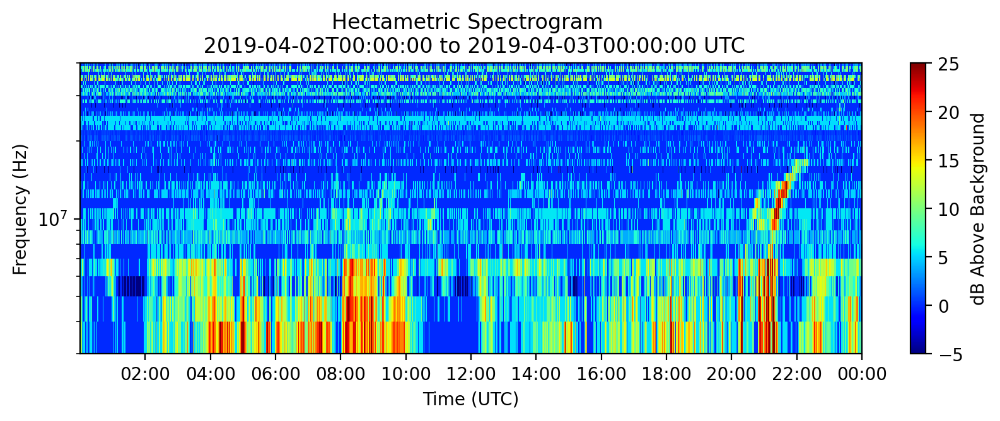

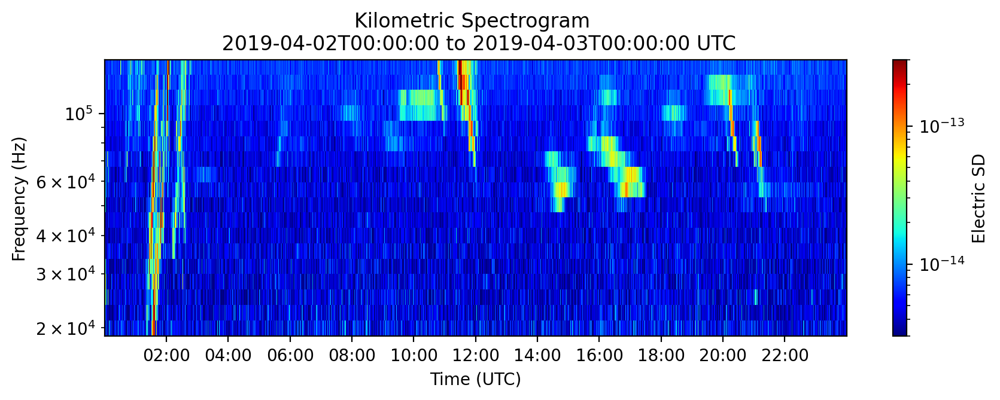

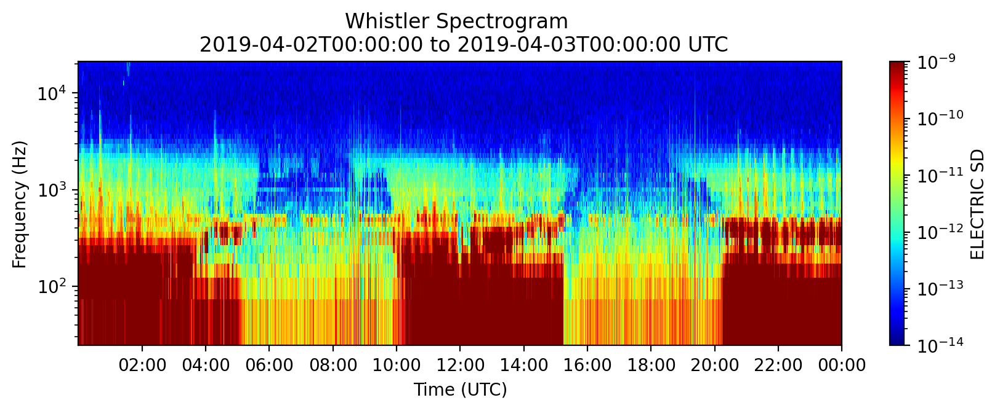

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.dates as mdates
from das2 import get_source
from matplotlib.ticker import LogLocator, LogFormatterMathtext

# —————————————————————————————————————————————
# CONFIGURATION
SERVER_URL   = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
START_TIME   = "2019-04-02T00:00:00"
END_TIME     = "2019-04-03T00:00:00"

# 1) Retrieve data (use only hect_data2 for Hectametric)
source = get_source(SERVER_URL)
whistler_data, kilometric_data, _, hect_data2 = source.get({
    'time': (START_TIME, END_TIME)
})

# Helper: extract time (1D), frequency (1D), and spec (2D: time x freq)
def extract_arrays(data):
    freq_arr = data['frequency']['center'].array
    freqs = freq_arr[0, :] if freq_arr.ndim > 1 else freq_arr
    time_arr = data['Time']['center'].array
    times = time_arr[:, 0] if time_arr.ndim > 1 else time_arr
    spec_arr = data['spec_dens']['center'].array
    spec = spec_arr.squeeze()
    if spec.shape[1] != freqs.size:
        spec = spec.T
    return times, freqs, spec

# Extract each dataset
times_hect, f_hect, s_hect = extract_arrays(hect_data2)
t_kilo,    f_kilo, s_kilo   = extract_arrays(kilometric_data)
t_whis,    f_whis, s_whis   = extract_arrays(whistler_data)

# —————————————————————————————————————————————
# 2) Compute dB above background for Hectametric & Kilometric

print(s_hect.shape)

# Hectametric: 10th‐percentile across time for each freq
bg_hect = np.percentile(s_hect, 10, axis=0, method='midpoint')       # shape (n_freq,)
eps_hect = np.nanmax(s_hect) * 1e-7
bg_hect = np.where(bg_hect <= 0, eps_hect, bg_hect)
dB_hect = 20 * np.log10(s_hect / bg_hect[None, :])  # still shape (time, freq)



# —————————————————————————————————————————————
# 3) Plot Hectametric dB spectrogram
fig_hect, ax_hect = plt.subplots(figsize=(10, 3), dpi=200)
mesh1 = ax_hect.pcolormesh(
    times_hect, f_hect, dB_hect.T,
    cmap='jet', shading='nearest', vmin=-5, vmax=25
)
ax_hect.set_yscale('log')
ax_hect.set_ylim(3e6, 40e6)
ax_hect.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax_hect.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_hect.set_xlabel('Time (UTC)')
ax_hect.set_ylabel('Frequency (Hz)')
ax_hect.set_title(f'Hectametric Spectrogram \n {START_TIME} to {END_TIME} UTC')
cbar1 = fig_hect.colorbar(mesh1, ax=ax_hect, label='dB Above Background')
plt.show()

# —————————————————————————————————————————————
# 4) Plot Kilometric dB spectrogram
fig_kilo, ax_kilo = plt.subplots(figsize=(10, 3), dpi=200)
mesh2 = ax_kilo.pcolormesh(
    t_kilo, f_kilo, s_kilo.T,
    cmap='jet', shading='auto',
    norm=LogNorm(vmin=3e-15, vmax=3e-13)
)
ax_kilo.set_yscale('log')
ax_kilo.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax_kilo.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_kilo.set_xlabel('Time (UTC)')
ax_kilo.set_ylabel('Frequency (Hz)')
ax_kilo.set_title(f'Kilometric Spectrogram \n {START_TIME} to {END_TIME} UTC')
cbar2 = fig_kilo.colorbar(mesh2, ax=ax_kilo, label='Electric SD')
plt.show()

# —————————————————————————————————————————————
# 5) (Optional) Whistler still in raw units
fig_whis, ax_whis = plt.subplots(figsize=(10, 3), dpi=200)
mesh3 = ax_whis.pcolormesh(
    t_whis, f_whis, s_whis.T,
    norm=LogNorm(vmin=1e-14, vmax=1e-9),
    cmap='jet', shading='auto'
)
ax_whis.set_yscale('log')
ax_whis.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax_whis.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_whis.set_xlabel('Time (UTC)')
ax_whis.set_ylabel('Frequency (Hz)')
ax_whis.set_title(f'Whistler Spectrogram \n {START_TIME} to {END_TIME} UTC')
cbar3 = fig_whis.colorbar(mesh3, ax=ax_whis, label='ELECTRIC SD')
plt.show()


In [ ]:
import numpy as np
import pandas as pd

def plot_plasma_freq(start_time: str, end_time:   str):
    """
    Load JADE electron spectrogram from a Hisaki-style ASCII file and
    optionally window it in time.

    Parameters
    ----------
    path : str
        Path to the JADE electron file (ASCII).
    start_time, end_time : str or None
        ISO strings like 'YYYY-MM-DDThh:mm:ss'. If None, unbounded on that side.

    Returns
    -------
    energies_eV : (N_E,) float ndarray
    times       : (N_T,) numpy.datetime64[ms] ndarray
    spec        : (N_T, N_E) float ndarray
        Windowed to [start_time, end_time] if provided (inclusive).
    """
    with open('ion_and_e_pa/2019092_jade_e.txt', 'r') as f:
        lines = f.readlines()

    # --- Parse energies from the first header line containing '(eV)' ---
    header = next(l for l in lines if l.lstrip().startswith('#'))
    tokens = header.strip().split()
    ev_idx = tokens.index('(eV)') + 1
    energies_eV = np.array(tokens[ev_idx:], dtype=float)

    # --- Parse time series rows (skip comment/blank lines) ---
    times_list, values_list = [], []
    for L in lines:
        s = L.strip()
        if not s or s.startswith('#'):
            continue
        parts = s.split()
        # Example format: 2019-04-02/17:05:00  v1 v2 v3 ...
        t = pd.to_datetime(parts[0], format='%Y-%m-%d/%H:%M:%S', utc=False)
        times_list.append(t)
        values_list.append([float(x) for x in parts[1:]])

    times = np.array(pd.to_datetime(times_list).astype('datetime64[ms]'))
    spec  = np.array(values_list, dtype=float)

    # --- Optional windowing (inclusive) ---
    if start_time is not None or end_time is not None:
        # Accept 'YYYY-MM-DDThh:mm:ss'
        t0 = np.datetime64(start_time) if start_time is not None else times.min()
        t1 = np.datetime64(end_time)   if end_time   is not None else times.max()
        mask = (times >= t0) & (times <= t1)
        # If window misses all data, keep arrays empty (caller can handle)
        times = times[mask]
        spec  = spec[mask, :]



START_TIME      = "2019-04-02T00:00:00"
END_TIME        = "2019-04-03T00:00:00"

plot_plasma_freq(START_TIME, END_TIME)


[2.82805514e-08 3.35358364e-08 6.59927944e-08 ... 2.12616987e-07
 2.70738213e-07 1.51881170e-07]


2


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_1901/2641793896.py:72: RuntimeWarning: divide by zero encountered in divide
  periods  = 1.0 / f_fft / 60.0               # minutes


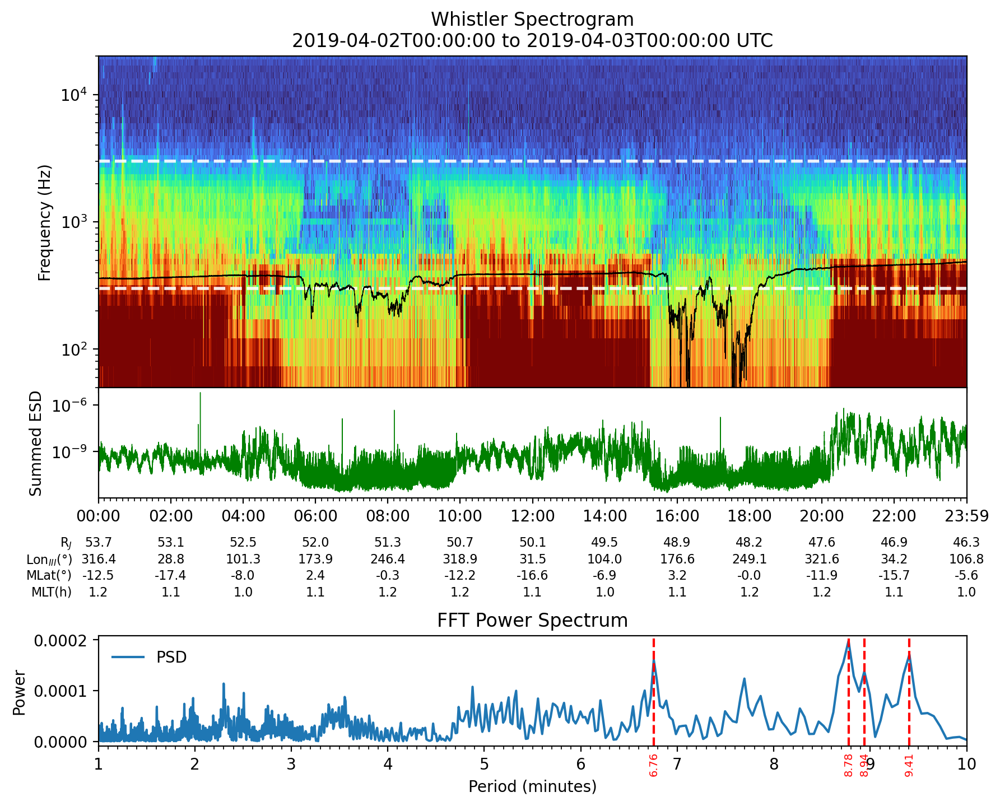

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator
from scipy.signal import find_peaks
from das2 import get_source
import matplotlib.patheffects as pe
from matplotlib.gridspec import GridSpec
import das2
# —————————————————————————————————————————————
# CONFIGURATION
SERVER_URL      = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
START_TIME      = "2019-04-02T00:00:00"
END_TIME        = "2019-04-03T00:00:00"

# Whistler band for summation (Hz)
WHIS_MIN        = 300
WHIS_MAX        = 3000

# FFT / PSD parameters
PERIOD_MIN      = 1      # minutes
PERIOD_MAX      = 10     # minutes
PEAK_DETECT_MIN = 2.5    # only label peaks ≥ this period
NUM_PEAKS       = 4      # top N peaks
FAP_GLOBAL      = 0.01   # global false‑alarm probability

# —————————————————————————————————————————————
# 1) Fetch whistler data
source = get_source(SERVER_URL)
whis, _, _, _ = source.get({
    'time': (START_TIME, END_TIME)
})

# 2) Extract time, frequency, and spectral density
def extract_arrays(d):
    f_arr = d['frequency']['center'].array
    freqs = f_arr[0,:] if f_arr.ndim>1 else f_arr
    t_arr = d['Time']['center'].array
    times = t_arr[:,0] if t_arr.ndim>1 else t_arr
    spec  = d['spec_dens']['center'].array.squeeze()
    if spec.shape[1] != freqs.size:
        spec = spec.T
    return np.array(times, dtype='datetime64[ms]'), freqs, spec

times, freqs, spec = extract_arrays(whis)

total_hours = (times[-1] - times[0]) / np.timedelta64(1, 'h')

tick_interval_h = 1 if total_hours <= 12 else 2

print(tick_interval_h)
# 3) Sum spectral density across the chosen band
mask_band = (freqs >= WHIS_MIN) & (freqs <= WHIS_MAX)
sum_sd    = spec[:, mask_band].sum(axis=1)

# 4) Build time axis in seconds for detrending
t0    = times[0]
t_sec = (times - t0) / np.timedelta64(1, 's')
dt    = np.median(np.diff(t_sec))

# 5) Detrend: fit and remove linear trend
coeff   = np.polyfit(t_sec, sum_sd, 1)
trend   = np.polyval(coeff, t_sec)
resid   = sum_sd - trend

# 6) FFT & Power Spectral Density
n        = len(resid)
fft_y    = np.fft.rfft(resid)
psd      = np.abs(fft_y)**2
f_fft    = np.fft.rfftfreq(n, dt)           # Hz
periods  = 1.0 / f_fft / 60.0               # minutes
mask_p   = (periods >= PERIOD_MIN) & (periods <= PERIOD_MAX)

# 7) Global threshold & peak detection
M        = np.count_nonzero(mask_p)
thr      = -np.var(resid, ddof=1) * np.log(FAP_GLOBAL / M)
psd_m    = psd[mask_p]
peaks, _ = find_peaks(psd_m)
sel      = peaks[np.argsort(psd_m[peaks])][-NUM_PEAKS:]
peak_periods = periods[mask_p][sel]
peak_periods = peak_periods[peak_periods >= PEAK_DETECT_MIN]
# 8) Plot: nested GridSpec

fig = plt.figure(figsize=(10, 8), dpi=200)
outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[4, 1], hspace=0.5)

# top “compound” axes: a 2×1 inside the first slot of outer_gs
inner_gs = outer_gs[0].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.0)
ax_spec = fig.add_subplot(inner_gs[0])
ax_ts   = fig.add_subplot(inner_gs[1], sharex=ax_spec)

# bottom FFT axis in the second slot of outer_gs
ax_fft  = fig.add_subplot(outer_gs[1])

# a) Spectrogram
pcm = ax_spec.pcolormesh(
    times, freqs, spec.T,
    norm=LogNorm(vmin=1e-14, vmax=1e-9), cmap='turbo', shading='nearest'
)
ax_spec.set_yscale('log')
ax_spec.set_facecolor('black')
ax_spec.plot(times, [WHIS_MIN]*len(times), '--w', lw=2, alpha=0.9)
ax_spec.plot(times, [WHIS_MAX]*len(times), '--w', lw=2, alpha=0.9)
ax_spec.set_ylabel('Frequency (Hz)')
ax_spec.set_title(f'Whistler Spectrogram\n{START_TIME} to {END_TIME} UTC')
efc_source = das2.get_source('tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2')
ds_efc = efc_source.get({'time': (START_TIME, END_TIME)})[0]
efc_freq = ds_efc['fce']['center'].array
efc_time = ds_efc['time']['center'].array
ax_spec.plot(efc_time, efc_freq, color='black', linewidth=0.5)
ax_spec.set_ylim(5e1, 2e4)
# hide bottom‐ticks on the spectrogram so it doesn’t duplicate with the series
ax_spec.tick_params(labelbottom=False)

# b) Summed time series (shares x with spec only)
ax_ts.plot(times, sum_sd, linewidth=0.5, color='green')
ax_ts.set_ylabel('Summed ESD')

def plasma_freq(density):
    return np.sqrt((density*1.60218e-19**2)/(9.10938e-31*8.85419e-12))




ax_ts.set_xlim(times[0], times[-1])
ax_ts.set_yscale('log')

major = mdates.HourLocator(interval=tick_interval_h)
minor = mdates.MinuteLocator(interval=10)
fmt   = mdates.DateFormatter('%H:%M')
ax_ts.xaxis.set_major_locator(major)
ax_ts.xaxis.set_minor_locator(minor)
ax_ts.xaxis.set_major_formatter(fmt)

# ─── Ephemeris rows below the summed time series ─────────────────────────────


# 1) fetch Jovicentric ephemeris at the same cadence dt (seconds)
eph_src = get_source('tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2')
ds_eph  = eph_src.get({'time': (START_TIME, END_TIME, int(dt))})[0]

rad   = ds_eph['radius']['center'].array
lon3  = ds_eph['long']['center'].array
mlatE = ds_eph['mlat']['center'].array
mltE  = ds_eph['mlt']['center'].array


# if MLT comes back as a timedelta, convert to hours
if mltE.dtype.kind == 'm':
    mltE = (mltE / np.timedelta64(1, 'h')).astype(float)

# 2) find the indices at every 2 h major tick
from matplotlib.ticker import FixedLocator

# ─── 2') build tick list including endpoints ────────────────────────────────
t0h = times[0].astype('datetime64[h]')
t1h = times[-1].astype('datetime64[h]') + np.timedelta64(1, 'h')
maj = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, 'h'))

# now include the true endpoints
all_ticks = np.unique(np.concatenate(([times[0]], maj, [times[-1]])))

# 2) convert them to Python datetimes, then to Matplotlib floats:
py_ticks      = [t.tolist() for t in all_ticks]       # t.tolist() gives a datetime.datetime
all_tick_nums = mdates.date2num(py_ticks)             # array of floats

# 3) feed those floats to your locators:
ax_ts.xaxis.set_major_locator(FixedLocator(all_tick_nums))
ax_ts.xaxis.set_major_formatter(fmt)

# 4) recompute the ephemeris indices on the original datetime64 array:
idx_eph = [np.argmin(np.abs(times - t64)) for t64 in all_ticks]
idx_eph = [np.argmin(np.abs(times - mt)) for mt in all_ticks]

# ─── 4') draw each ephemeris row with the same all_ticks ───────────────────
row_lbls   = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
row_arrays = [rad, lon3, mlatE, mltE]     # raw full arrays
row_spacing = 0.15  # vertical spacing between rows

for j, (label, arr) in enumerate(zip(row_lbls, row_arrays)):
    off = -row_spacing * (j + 2)
    sax = ax_ts.secondary_xaxis(off, functions=(lambda x:x, lambda x:x))

    # force identical tick positions
    sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
    # pull out the matching ephemeris values
    vals = arr[idx_eph]
    sax.set_xticklabels([f"{v:.1f}" for v in vals],
                         rotation=0, va='top', fontsize=8)

    sax.spines['bottom'].set_visible(False)
    sax.tick_params(axis='x', length=0)
    sax.xaxis.set_ticks_position('bottom')
    sax.xaxis.set_label_position('bottom')
    txt = sax.set_xlabel(label, fontsize=8, labelpad=-8.5, loc='left')
    txt.set_x(-0.03)
    txt.set_ha('right')


# c) FFT Power Spectrum (independent x-axis)
ax_fft.plot(periods[mask_p], psd_m*n, label='PSD')
ymin, ymax = ax_fft.get_ylim()
for p in peak_periods:
    ax_fft.axvline(p, ls='--', color='red')
    ax_fft.text(
        p,                         # x in data coords
        -0.05,                     # y in axis coords (5% below x‐axis)
        f'{p:.2f}',
        transform=ax_fft.get_xaxis_transform(),  # data x, axes‐fraction y
        rotation=90,               # vertical text
        va='top',               # anchor at bottom of the text box
        ha='center',               # centred on the tick
        color='red',
        fontsize=7
    )

ax_fft.set_xlim(PERIOD_MIN, PERIOD_MAX)
ax_fft.set_xlabel('Period (minutes)')
ax_fft.set_ylabel('Power')
ax_fft.set_title('FFT Power Spectrum')
ax_fft.legend(loc='upper left', frameon=False)
ax_fft.xaxis.set_major_locator(MultipleLocator(1))
ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

plt.show()

/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/numpy/lib/function_base.py:4824: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_4150/2855281168.py:82: RuntimeWarning: divide by zero encountered in divide
  periods = 1.0 / f_fft / 60.0


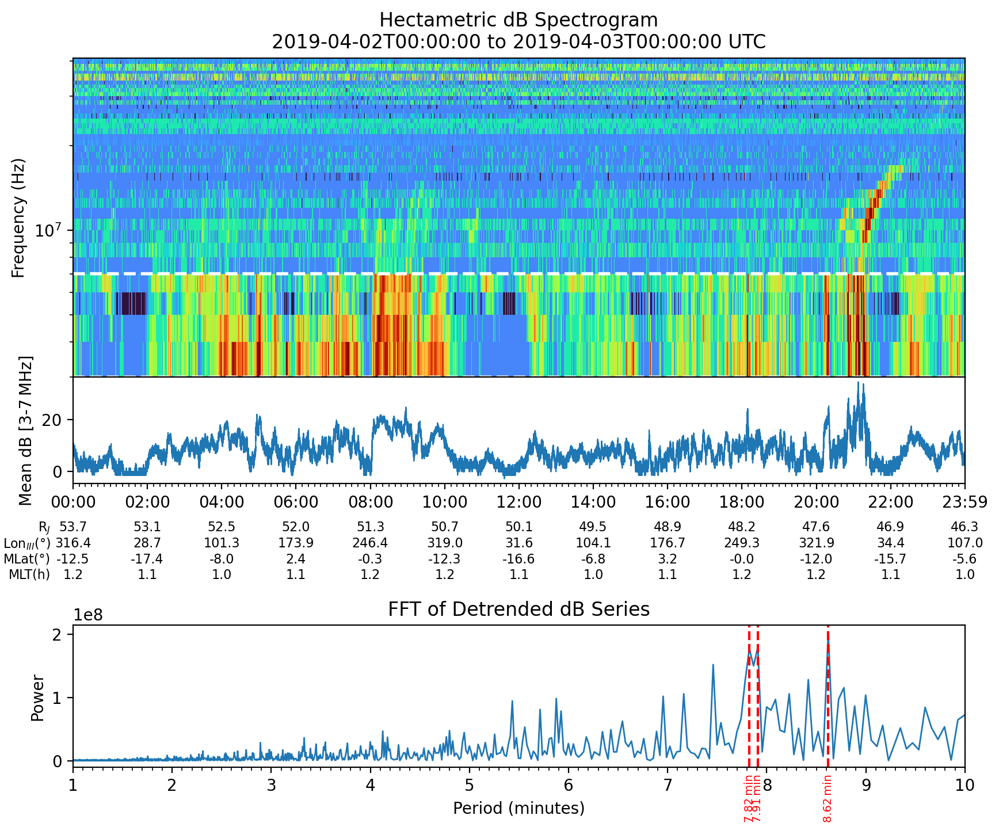

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from scipy.signal import find_peaks
from das2 import get_source
from matplotlib.gridspec import GridSpec

# —————————————————————————————————————————————
# CONFIGURATION
SERVER_URL      = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
START_TIME      = "2019-04-02T00:00:00"
END_TIME        = "2019-04-03T00:00:00"

# Hectametric dB spectrogram color limits
DB_VMIN         = -5
DB_VMAX         = 25

# Frequency band for PSD (Hz)
HECT_MIN        = 3e6    # 3 MHz
HECT_MAX        = 7e6    # 7 MHz

# FFT / PSD parameters
PERIOD_MIN      = 1      # minutes
PERIOD_MAX      = 10     # minutes
PEAK_DETECT_MIN = 2.5    # only mark peaks ≥ this period (min)
NUM_PEAKS       = 3      # number of top peaks to label
FAP_GLOBAL      = 0.01   # global false‑alarm probability

# —————————————————————————————————————————————
# 1) Fetch Hectametric data
source = get_source(SERVER_URL)
_, _, _, hect = source.get({'time': (START_TIME, END_TIME)})

# 2) Extract arrays
def extract_arrays(d):
    f_arr = d['frequency']['center'].array
    freqs = f_arr[0,:] if f_arr.ndim>1 else f_arr
    t_arr = d['Time']['center'].array
    times = t_arr[:,0] if t_arr.ndim>1 else t_arr
    S = d['spec_dens']['center'].array.squeeze()
    if S.shape[1] != freqs.size:
        S = S.T
    return np.array(times, dtype='datetime64[ms]'), freqs, S

times, freqs, spec = extract_arrays(hect)

# 2a) decide tick spacing
total_hours    = (times[-1] - times[0]) / np.timedelta64(1, 'h')
tick_interval_h = 1 if total_hours <= 12 else 2

# 3) dB above 10th‑percentile background
S_clean = spec.astype(float)
mask_bad = (S_clean <= 0) | (~np.isfinite(S_clean))
S_clean[mask_bad] = np.nan
bg   = np.nanpercentile(S_clean, 10, axis=0)
eps  = np.nanmax(S_clean) * 1e-6
bg   = np.where(bg <= 0, eps, bg)
dB_hect = 20 * np.log10(spec / bg[None, :])

# 4) Band‑average dB time series
band_mask = (freqs >= HECT_MIN) & (freqs <= HECT_MAX)
dB_band   = np.nanmean(dB_hect[:, band_mask], axis=1)

# 5) Time in sec for detrending
t0    = times[0]
t_sec = (times - t0) / np.timedelta64(1, 's')
dt    = np.median(np.diff(t_sec))

# 6) Detrend & variance
coeff    = np.polyfit(t_sec, dB_band, 1)
trend    = np.polyval(coeff, t_sec)
residual = dB_band - trend
sigma2   = np.nanvar(residual, ddof=1)

# 7) FFT & PSD
n      = len(residual)
fft_y  = np.fft.rfft(residual)
psd    = np.abs(fft_y)**2
f_fft  = np.fft.rfftfreq(n, dt)
periods = 1.0 / f_fft / 60.0
p_mask  = (periods >= PERIOD_MIN) & (periods <= PERIOD_MAX)

# 8) Threshold & peak detection
M        = np.count_nonzero(p_mask)
P_thr    = -sigma2 * np.log(FAP_GLOBAL / M)
psd_mask = psd[p_mask]
peaks, _ = find_peaks(psd_mask)
sel      = peaks[np.argsort(psd_mask[peaks])][-NUM_PEAKS:]
peak_periods = periods[p_mask][sel]
peak_periods = peak_periods[peak_periods >= PEAK_DETECT_MIN]

# ─── Plot: nested GridSpec ─────────────────────────────────────────────────

fig = plt.figure(figsize=(10, 8), dpi=200)
outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[3, 1], hspace=0.5)

# top compound: spectrogram + band-avg
inner_gs = outer_gs[0].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.0)
ax_spec  = fig.add_subplot(inner_gs[0])
ax_ts    = fig.add_subplot(inner_gs[1], sharex=ax_spec)

# bottom: FFT
ax_fft   = fig.add_subplot(outer_gs[1])

# (a) dB spectrogram
pcm = ax_spec.pcolormesh(
    times, freqs, dB_hect.T,
    cmap='turbo', shading='nearest',
    vmin=DB_VMIN, vmax=DB_VMAX
)
ax_spec.set_yscale('log')
ax_spec.set_facecolor('black')
ax_spec.plot(times, [HECT_MIN]*len(times), '--w', lw=2)
ax_spec.plot(times, [HECT_MAX]*len(times), '--w', lw=2)
ax_spec.set_ylabel('Frequency (Hz)')
ax_spec.set_title(f'Hectametric dB Spectrogram\n{START_TIME} to {END_TIME} UTC')
ax_spec.tick_params(labelbottom=False)

# (b) Band‑averaged dB
ax_ts.plot(times, dB_band, color='C0', linewidth=0.8)
ax_ts.set_ylabel(f'Mean dB [{HECT_MIN/1e6:.0f}-{HECT_MAX/1e6:.0f} MHz]')
ax_ts.set_xlim(times[0], times[-1])

# build unified tick list (endpoints + majors)
t0h        = times[0].astype('datetime64[h]')
t1h        = times[-1].astype('datetime64[h]') + np.timedelta64(1, 'h')
maj        = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, 'h'))
all_ticks  = np.unique(np.concatenate(([times[0]], maj, [times[-1]])))
py_ticks   = [t.tolist() for t in all_ticks]
all_nums   = mdates.date2num(py_ticks)

fmt = mdates.DateFormatter('%H:%M')
ax_ts.xaxis.set_major_locator(FixedLocator(all_nums))
ax_ts.xaxis.set_major_formatter(fmt)
ax_ts.xaxis.set_minor_locator(mdates.MinuteLocator(interval=10))

# ─── Ephemeris rows under band‑avg ──────────────────────────────────────────

eph_src = get_source('tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2')
ds_eph  = eph_src.get({'time': (START_TIME, END_TIME, int(dt))})[0]

rad   = ds_eph['radius']['center'].array
lon3  = ds_eph['long']['center'].array
mlatE = ds_eph['mlat']['center'].array
mltE  = ds_eph['mlt']['center'].array
if mltE.dtype.kind == 'm':
    mltE = (mltE / np.timedelta64(1, 'h')).astype(float)

row_lbls   = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
row_arrays = [rad, lon3, mlatE, mltE]
row_spacing = 0.15

for j, (label, arr) in enumerate(zip(row_lbls, row_arrays)):
    off = -row_spacing * (j + 2)
    sax = ax_ts.secondary_xaxis(off, functions=(lambda x:x, lambda x:x))
    sax.xaxis.set_major_locator(FixedLocator(all_nums))
    vals = arr[[np.argmin(np.abs(times - t64)) for t64 in all_ticks]]
    sax.set_xticklabels([f"{v:.1f}" for v in vals],
                        rotation=0, va='top', fontsize=8)
    sax.spines['bottom'].set_visible(False)
    sax.tick_params(axis='x', length=0)
    sax.xaxis.set_ticks_position('bottom')
    sax.xaxis.set_label_position('bottom')
    txt = sax.set_xlabel(label, fontsize=8, labelpad=-8.5, loc='left')
    txt.set_x(-0.025)  # slightly to the right
    txt.set_ha('right')

# (c) FFT Power Spectrum
ax_fft.plot(periods[p_mask], psd_mask, color='C0', linewidth=1)
ymin, ymax = ax_fft.get_ylim()
for p in peak_periods:
    ax_fft.axvline(p, ls='--', color='red')
    ax_fft.text(
        p, -0.05, f'{p:.2f} min',
        transform=ax_fft.get_xaxis_transform(),
        rotation=90, va='top', ha='center',
        color='red', fontsize=7
    )

ax_fft.set_xlim(PERIOD_MIN, PERIOD_MAX)
ax_fft.set_xlabel('Period (minutes)')
ax_fft.set_ylabel('Power')
ax_fft.set_title('FFT of Detrended dB Series')
ax_fft.xaxis.set_major_locator(MultipleLocator(1))
ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

plt.show()


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_4488/4142651343.py:76: RuntimeWarning: divide by zero encountered in divide
  periods  = 1.0 / freqs / 60.0


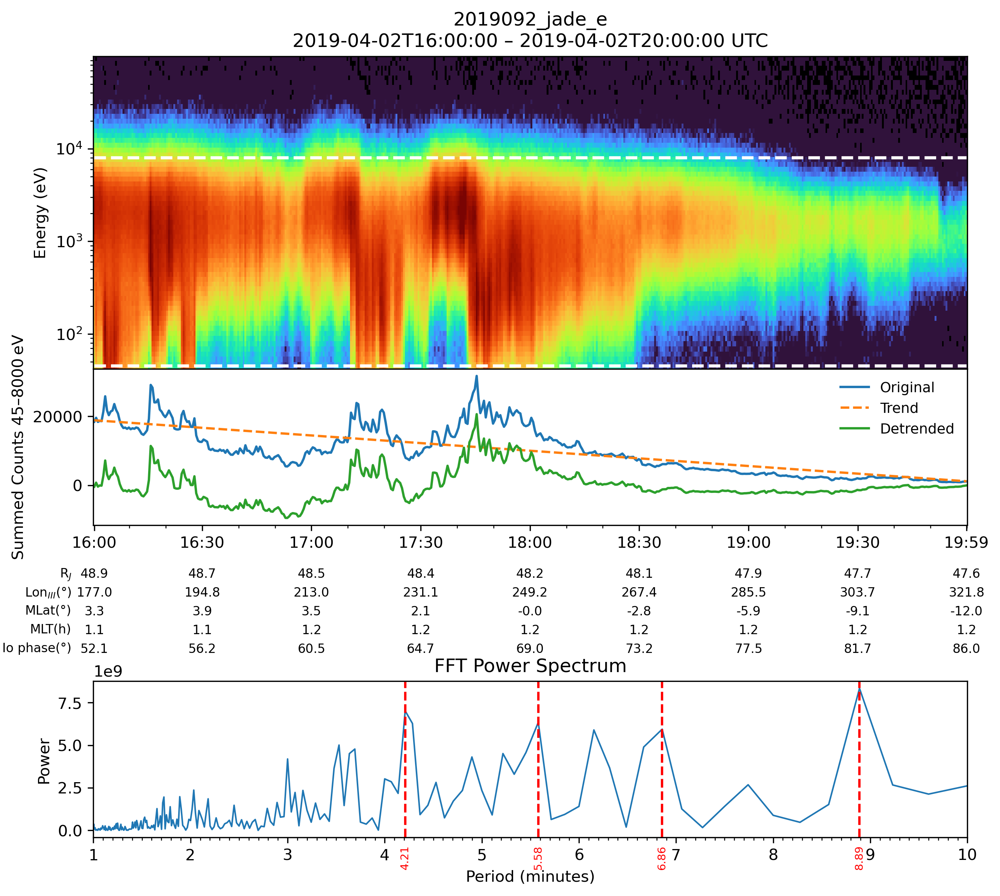

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from scipy.signal import find_peaks
from das2 import get_source
from matplotlib.gridspec import GridSpec

# —————————————————————————————————————————————
# CONFIGURATION
FILEPATH        = 'ion_and_e_pa/2019092_jade_e.txt'
OUT_DIR         = 'Segment Analysis Figures'
os.makedirs(OUT_DIR, exist_ok=True)

START_TIME      = '2019-04-02T16:00:00'
END_TIME        = '2019-04-02T20:00:00'

ENERGY_MIN      = 45      # eV
ENERGY_MAX      = 8000    # eV

PERIOD_MIN      = 1       # minutes
PERIOD_MAX      = 10      # minutes
PEAK_DETECT_MIN = 2.5     # minutes
NUM_PEAKS       = 4
FAP_GLOBAL      = 0.01

# —————————————————————————————————————————————
# 1) Read and parse the JADE file
with open(FILEPATH, 'r') as f:
    lines = f.readlines()

header = next(l for l in lines if l.lstrip().startswith('#'))
tokens = header.strip().split()
ev_idx = tokens.index('(eV)') + 1
energies = np.array(tokens[ev_idx:], dtype=float)

times_list, values_list = [], []
for L in lines:
    s = L.strip()
    if not s or s.startswith('#'):
        continue
    parts = s.split()
    times_list.append(pd.to_datetime(parts[0], format='%Y-%m-%d/%H:%M:%S'))
    values_list.append(list(map(float, parts[1:])))
times = np.array(times_list, dtype='datetime64[ms]')
spec  = np.array(values_list)

# 2) Window selection
start_ts  = np.datetime64(pd.to_datetime(START_TIME))
end_ts    = np.datetime64(pd.to_datetime(END_TIME))
mask_t    = (times >= start_ts) & (times <= end_ts)
times_win = times[mask_t]
spec_win  = spec[mask_t, :]

# 3) Summed counts over energy band
mask_e     = (energies >= ENERGY_MIN) & (energies <= ENERGY_MAX)
avg_counts = spec_win[:, mask_e].sum(axis=1)

# 4) Detrend & residual
t0        = times_win[0]
t_sec_win = (times_win - t0) / np.timedelta64(1, 's')
dt        = np.median(np.diff(t_sec_win))
coeff     = np.polyfit(t_sec_win, avg_counts, 1)
trend     = np.polyval(coeff, t_sec_win)
residual  = avg_counts - trend
sigma2    = np.var(residual, ddof=1)

# 5) FFT & PSD
n        = len(residual)
fft_y    = np.fft.rfft(residual)
psd      = np.abs(fft_y)**2
freqs    = np.fft.rfftfreq(n, dt)
periods  = 1.0 / freqs / 60.0
mask_p   = (periods >= PERIOD_MIN) & (periods <= PERIOD_MAX)

# 6) Peak detection
M             = np.count_nonzero(mask_p)
P_thr_global  = -sigma2 * np.log(FAP_GLOBAL / M)
psd_mask      = psd[mask_p]
peaks, _      = find_peaks(psd_mask)
top_peaks     = peaks[np.argsort(psd_mask[peaks])][-NUM_PEAKS:]
peak_periods  = periods[mask_p][top_peaks]
peak_periods  = peak_periods[peak_periods >= PEAK_DETECT_MIN]

# 7) Dynamic tick & ephemeris interval
total_hours     = (times_win[-1] - times_win[0]) / np.timedelta64(1, 'h')
tick_interval_h = 1 if total_hours <= 12 else 2

# under 4 h → 30 min steps; otherwise hourly or 2‑hourly
if total_hours <= 4:
    eph_step = np.timedelta64(30, 'm')
else:
    eph_step = np.timedelta64(tick_interval_h, 'h')

# —————————————————————————————————————————————
# 8) Plot: nested GridSpec
basename = os.path.splitext(os.path.basename(FILEPATH))[0]

fig = plt.figure(figsize=(10, 9), dpi=300)
outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[3, 1], hspace=0.5)

# top compound: spectrogram + summed counts
inner_gs = outer_gs[0].subgridspec(2, 1, height_ratios=[2, 1], hspace=0.0)
ax_spec = fig.add_subplot(inner_gs[0])
ax_avg  = fig.add_subplot(inner_gs[1], sharex=ax_spec)

# bottom: FFT
ax_fft  = fig.add_subplot(outer_gs[1])

# (a) Spectrogram
pcm = ax_spec.pcolormesh(
    times_win, energies, spec_win.T,
    norm=LogNorm(vmin=1e1, vmax=1e3),
    cmap='turbo', shading='auto'
)
ax_spec.set_yscale('log')
ax_spec.set_facecolor('black')
ax_spec.plot(times_win, [ENERGY_MIN]*len(times_win),'--w', lw=2)
ax_spec.plot(times_win, [ENERGY_MAX]*len(times_win),'--w', lw=2)
ax_spec.set_ylabel('Energy (eV)')
ax_spec.set_title(f'{basename}\n{START_TIME} – {END_TIME} UTC')
ax_spec.tick_params(labelbottom=False)

# (b) Summed counts & trend & residual
ax_avg.plot(times_win, avg_counts, label='Original', color='C0')
ax_avg.plot(times_win, trend,      linestyle='--', color='C1', label='Trend')
ax_avg.plot(times_win, residual,   color='C2', label='Detrended')
ax_avg.set_ylabel(f'Summed Counts {ENERGY_MIN}–{ENERGY_MAX} eV')
ax_avg.legend(frameon=False, fontsize=9)

# build tick list (start, end, and every eph_step)
t0h      = times_win[0].astype('datetime64[h]')
t1h      = times_win[-1].astype('datetime64[h]') + np.timedelta64(1, 'h')
maj      = np.arange(t0h, t1h, eph_step)
all_ticks = np.unique(np.concatenate(([times_win[0]], maj, [times_win[-1]])))
py_ticks  = [pd.to_datetime(t).to_pydatetime() for t in all_ticks]
tick_nums = mdates.date2num(py_ticks)

ax_avg.xaxis.set_major_locator(FixedLocator(tick_nums))
ax_avg.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_avg.xaxis.set_minor_locator(mdates.MinuteLocator(interval=10))
plt.setp(ax_avg.get_xticklabels(which='major'), rotation=0)

# (c) Ephemeris rows under summed counts
eph_src = get_source('tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2')
ds_eph  = eph_src.get({'time': (START_TIME, END_TIME, int(dt))})[0]

rad   = ds_eph['radius']['center'].array
lon3  = ds_eph['long']['center'].array
mlatE = ds_eph['mlat']['center'].array
mltE  = ds_eph['mlt']['center'].array
ioE   = ds_eph['io_phase']['center'].array
if mltE.dtype.kind == 'm':
    mltE = (mltE / np.timedelta64(1, 'h')).astype(float)

row_lbls   = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)", "Io phase(°)"]
row_arrays = [rad, lon3, mlatE, mltE, ioE]
row_spacing = 0.12

for j, (label, arr) in enumerate(zip(row_lbls, row_arrays)):
    off = -row_spacing * (j + 2)
    sax = ax_avg.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
    sax.xaxis.set_major_locator(FixedLocator(tick_nums))
    idxs = [np.argmin(np.abs(times_win - t64)) for t64 in all_ticks]
    vals = arr[idxs]
    sax.set_xticklabels([f"{v:.1f}" for v in vals],
                        rotation=0, va='top', fontsize=8)
    sax.spines['bottom'].set_visible(False)
    sax.tick_params(axis='x', length=0)
    sax.xaxis.set_ticks_position('bottom')
    sax.xaxis.set_label_position('bottom')
    txt = sax.set_xlabel(label, fontsize=8, labelpad=-8.5, loc='left')
    txt.set_x(-0.025)
    txt.set_ha('right')

# (d) FFT Power Spectrum
ax_fft.plot(periods[mask_p], psd_mask, color='C0', linewidth=1)
ymin, ymax = ax_fft.get_ylim()
for p in peak_periods:
    ax_fft.axvline(p, ls='--', color='red')
    ax_fft.text(
        p, -0.05, f'{p:.2f}',
        transform=ax_fft.get_xaxis_transform(),
        rotation=90, va='top', ha='center',
        color='red', fontsize=7
    )

ax_fft.set_xlim(PERIOD_MIN, PERIOD_MAX)
ax_fft.set_xlabel('Period (minutes)')
ax_fft.set_ylabel('Power')
ax_fft.set_title('FFT Power Spectrum')
ax_fft.xaxis.set_major_locator(MultipleLocator(1))
ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

plt.show()


In [ ]:
import pdr

data = pdr.read('Data_Files/20190402 All Data/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01.LBL')

data.keys()
labels = data['LABEL']
table = data['TABLE']




/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/pdr/bit_handling.py:174: UserWarning: Data type LSB_UNSIGNED_INTEGER incompatible for bit column. Changing to MSB_BIT_STRING.
  warnings.warn(


AttributeError: 'DataFrame' object has no attribute 'show'

In [16]:
import pdr
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)

test_file_table = pdr.read('Data_Files/20190402 All Data/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01.DAT')


print(test_file_table['LABEL'])
table = test_file_table['TABLE']

test = test_file_table['TABLE']


test_2 = test['DATA_1']

test.head()



PDS_VERSION_ID = PDS3                                                         
DATA_SET_ID    = "JNO-J/SW-JAD-5-CALIBRATED-V1.0"                             
                                                                              
/* Input file  : JAD_L50_LRS_ELC_ANY_DEF_2019092_V01.DAT */                   
/* File written: 2023/06/07 18:58:35 local time  */                           
                                                                              
STANDARD_DATA_PRODUCT_ID =     "L50_LRS_ELC_ANY_DEF"                          
PRODUCT_ID               = "JAD_L50_LRS_ELC_ANY_DEF_2019092"                  
PRODUCT_VERSION_ID       = "01"                                               
PRODUCT_TYPE             = "DATA"                                             
PRODUCT_CREATION_TIME    = 2023-159T00:58:35 /* UTC 2023-06-08 */             
PROCESSING_LEVEL_ID      = "5"                                                
                                                    

/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/pdr/bit_handling.py:174: UserWarning: Data type LSB_UNSIGNED_INTEGER incompatible for bit column. Changing to MSB_BIT_STRING.
  warnings.warn(


,DIM0_UTC,PACKETID,DIM0_UTC_UPPER,PACKET_MODE,DIM0_UTC_LOWER,PACKET_SPECIES,ACCUMULATION_TIME,DATA_UNITS,SOURCE_BACKGROUND,SPARE_ZEROS,SOURCE_MAG,SOURCE_JADE_METAKERNEL,SOURCE_JADE_CALIB,FSW_VERSION,LUT_VERSION,LUT_VERSION_SUB_LETTER,LUT_SWEEP_TABLE,FILE_VERSION,SC_POS_R,SC_POS_R_UPPER,SC_POS_R_LOWER,SC_POS_LAT,SC_POS_LAT_UPPER,SC_POS_LAT_LOWER,SC_POS_LOCAL_TIME,SC_POS_LOCAL_TIME_UPPER,SC_POS_LOCAL_TIME_LOWER,SC_POS_SYSIII_ELONG,SC_POS_SYSIII_ELONG_UPPER,SC_POS_SYSIII_ELONG_LOWER,SC_POS_JUPITER_J2000XYZ_0,SC_POS_JUPITER_J2000XYZ_1,SC_POS_JUPITER_J2000XYZ_2,SC_VEL_JUPITER_J2000XYZ_0,SC_VEL_JUPITER_J2000XYZ_1,SC_VEL_JUPITER_J2000XYZ_2,SC_VEL_ANGULAR_J2000XYZ_0,SC_VEL_ANGULAR_J2000XYZ_1,SC_VEL_ANGULAR_J2000XYZ_2,SC_SPIN_PERIOD,SC_SPIN_PHASE,SC_SPIN_PHASE_UPPER,SC_SPIN_PHASE_LOWER,DESPUN_SC_TO_J2000_0,DESPUN_SC_TO_J2000_1,DESPUN_SC_TO_J2000_2,DESPUN_SC_TO_J2000_3,DESPUN_SC_TO_J2000_4,DESPUN_SC_TO_J2000_5,DESPUN_SC_TO_J2000_6,DESPUN_SC_TO_J2000_7,DESPUN_SC_TO_J2000_8,J2000_TO_JSSXYZ_0,J2000_TO_JSSXYZ_1,J2000_TO_JSSXYZ_2,J2000_TO_JSSXYZ_3,J2000_TO_JSSXYZ_4,J2000_TO_JSSXYZ_5,J2000_TO_JSSXYZ_6,J2000_TO_JSSXYZ_7,J2000_TO_JSSXYZ_8,J2000_TO_JSSRTP_0,J2000_TO_JSSRTP_1,J2000_TO_JSSRTP_2,J2000_TO_JSSRTP_3,J2000_TO_JSSRTP_4,J2000_TO_JSSRTP_5,J2000_TO_JSSRTP_6,J2000_TO_JSSRTP_7,J2000_TO_JSSRTP_8,MCP_VOLTAGE,ISSUES,TIMESTAMP_WHOLE,TIMESTAMP_SUB,DATA_0,DATA_1,DATA_2,DATA_3,DATA_4,DATA_5,DATA_6,DATA_7,DATA_8,DATA_9,DATA_10,DATA_11,DATA_12,DATA_13,DATA_14,DATA_15,DATA_16,DATA_17,DATA_18,DATA_19,DATA_20,DATA_21,DATA_22,DATA_23,DATA_24,DATA_25,DATA_26,DATA_27,DATA_28,DATA_29,DATA_30,DATA_31,DATA_32,DATA_33,DATA_34,DATA_35,DATA_36,DATA_37,DATA_38,DATA_39,DATA_40,DATA_41,DATA_42,DATA_43,DATA_44,DATA_45,DATA_46,DATA_47,DATA_48,DATA_49,DATA_50,DATA_51,DATA_52,DATA_53,DATA_54,DATA_55,DATA_56,DATA_57,DATA_58,DATA_59,DATA_60,DATA_61,DATA_62,DATA_63,DATA_64,DATA_65,DATA_66,DATA_67,DATA_68,DATA_69,DATA_70,DATA_71,DATA_72,DATA_73,DATA_74,DATA_75,DATA_76,DATA_77,DATA_78,DATA_79,DATA_80,DATA_81,DATA_82,DATA_83,DATA_84,DATA_85,DATA_86,DATA_87,DATA_88,DATA_89,DATA_90,DATA_91,DATA_92,DATA_93,DATA_94,DATA_95,DATA_96,DATA_97,DATA_98,DATA_99,DATA_100,DATA_101,DATA_102,DATA_103,DATA_104,DATA_105,DATA_106,DATA_107,DATA_108,DATA_109,DATA_110,DATA_111,DATA_112,DATA_113,DATA_114,DATA_115,DATA_116,DATA_117,DATA_118,DATA_119,DATA_120,DATA_121,DATA_122,DATA_123,DATA_124,DATA_125,DATA_126,DATA_127,DATA_128,DATA_129,DATA_130,DATA_131,DATA_132,DATA_133,DATA_134,DATA_135,DATA_136,DATA_137,DATA_138,DATA_139,DATA_140,DATA_141,DATA_142,DATA_143,DATA_144,DATA_145,DATA_146,DATA_147,DATA_148,DATA_149,DATA_150,DATA_151,DATA_152,DATA_153,DATA_154,DATA_155,DATA_156,DATA_157,DATA_158,DATA_159,DATA_160,DATA_161,DATA_162,DATA_163,DATA_164,DATA_165,DATA_166,DATA_167,DATA_168,DATA_169,DATA_170,DATA_171,DATA_172,DATA_173,DATA_174,DATA_175,DATA_176,DATA_177,DATA_178,DATA_179,DATA_180,DATA_181,DATA_182,DATA_183,DATA_184,DATA_185,DATA_186,DATA_187,DATA_188,DATA_189,DATA_190,DATA_191,DATA_192,DATA_193,DATA_194,DATA_195,DATA_196,DATA_197,DATA_198,DATA_199,DATA_200,DATA_201,DATA_202,DATA_203,DATA_204,DATA_205,DATA_206,DATA_207,DATA_208,DATA_209,DATA_210,DATA_211,DATA_212,DATA_213,DATA_214,DATA_215,DATA_216,DATA_217,DATA_218,DATA_219,DATA_220,DATA_221,DATA_222,DATA_223,DATA_224,DATA_225,DATA_226,DATA_227,DATA_228,DATA_229,DATA_230,DATA_231,DATA_232,DATA_233,DATA_234,DATA_235,DATA_236,DATA_237,DATA_238,DATA_239,DATA_240,DATA_241,DATA_242,DATA_243,DATA_244,DATA_245,DATA_246,DATA_247,DATA_248,DATA_249,DATA_250,DATA_251,DATA_252,DATA_253,DATA_254,DATA_255,DATA_256,DATA_257,DATA_258,DATA_259,DATA_260,DATA_261,DATA_262,DATA_263,DATA_264,DATA_265,DATA_266,DATA_267,DATA_268,DATA_269,DATA_270,DATA_271,DATA_272,DATA_273,DATA_274,DATA_275,DATA_276,DATA_277,DATA_278,DATA_279,DATA_280,DATA_281,DATA_282,DATA_283,DATA_284,DATA_285,DATA_286,DATA_287,DATA_288,DATA_289,DATA_290,DATA_291,DATA_292,DATA_293,DATA_294,DATA_295,DATA_296,DATA_297,DATA_298,DATA_299,DATA_300,DATA_301,DATA_302,DATA_303,DATA_304,DATA_305,DATA_3